<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Where did the default workspace’s spend go?

**Does a cost report still reconcile after we attach workspace names?** An inner
join looks natural, but the default workspace appears as a NULL ID in the cost
report and has no row in the workspace directory. We will measure the resulting
gap, recover it without hiding unknown IDs, and examine how the gap changes over time.

**Synthetic local data, real worker.** A loopback HTTP fixture supplies invented
ledger entries for 1–7 September 2026 UTC. They are neither recorded account data
nor model prices. The actual SHA-pinned Anthropic worker parses and pages those
responses through Haybarn/VGI. No real credentials, account requests, or model
calls are involved. Initial package and extension downloads need internet access.

## Choose the report window

`REPORT_DAYS` is an integer from **1 to 7**, starting at 2026-09-01 00:00 UTC.
The start is inclusive and the end exclusive; only full UTC days are supported.
Restart the kernel and run all cells after editing. The final experiment changes
only this value from **7 to 3**.

In [1]:
REPORT_DAYS = 7  # whole UTC days from 2026-09-01; accepted range 1–7

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import COLORS, chart, close_fixture, configure, prose, theme

fixture, previous_url, start_at, end_at = configure(REPORT_DAYS)
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-anthropic-portable-92ivm85t/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-anthropic-portable-92ivm85t/pyproject.toml.

## Connect to the worker

The literal launch location installs a remotely available Git revision with the
compatible SDK versions documented in the guide. `VGI_ANTHROPIC_BASE_URL` is set to the local
fixture before the worker starts; the fixture never forwards requests. The SQL
secret contains a **public dummy value**, accepted only by this fixture.

`ATTACH` registers the secret type, so the secret is created afterward.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'anthropic' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --from git+https://github.com/Query-farm/vgi-anthropic@4da037833b6737c47ffd5ff4cf677c2a947ec7fb vgi-anthropic');
CREATE SECRET notebook_fixture (TYPE anthropic_admin, api_key 'notebook-synthetic-key-not-a-credential');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


In [4]:
prose(
    f"**Synthetic fixture:** `{fixture.url}` · **UTC window:** {start_at} ≤ timestamp < {end_at}. "
    f"Haybarn {haybarn.__version__}; worker revision `4da0378`. The fixture accepts only the "
    "workspace directory and cost report endpoints used below."
)

**Synthetic fixture:** `http://127.0.0.1:51940` · **UTC window:** 2026-09-01T00:00:00+00:00 ≤ timestamp < 2026-09-08T00:00:00+00:00. Haybarn 2.0.0rc11; worker revision `4da0378`. The fixture accepts only the workspace directory and cost report endpoints used below.

## Keep the report grain explicit

Materialize the workspace directory and cost report once. Explicit grouping by
`workspace_id` matters: a NULL in an **ungrouped** report means “all workspaces,”
whereas a NULL in this **grouped** report represents the default workspace.
Do not infer the default workspace from an ungrouped total.

The worker exposes exact decimal cents and USD. SQL preserves that precision for
reconciliation; plotting converts already-computed values to display numbers.

In [5]:
%%sql
CREATE TABLE workspace_directory AS
SELECT id, name, archived_at FROM anthropic.workspaces;
CREATE TABLE report_lines AS
SELECT bucket_start AS starting_at, bucket_end AS ending_at, workspace_id, currency, amount_cents, amount_usd
FROM anthropic.cost_report('{{start_at}}', ending_at => '{{end_at}}',
                           group_by => ['workspace_id']);
CREATE TABLE report_totals AS
SELECT bucket_start AS starting_at, bucket_end AS ending_at, currency, amount_cents, amount_usd
FROM anthropic.cost_report('{{start_at}}', ending_at => '{{end_at}}', group_by => []);
SELECT starting_at::DATE AS utc_day, workspace_id, currency, amount_cents, amount_usd
FROM report_lines ORDER BY starting_at, workspace_id NULLS LAST LIMIT 9;

,utc_day,workspace_id,currency,amount_cents,amount_usd
0,2026-09-01,wrkspc_prod,USD,6000.0,60.0
1,2026-09-01,wrkspc_stage,USD,2000.0,20.0
2,2026-09-01,None,USD,1200.0,12.0
3,2026-09-02,wrkspc_prod,USD,6500.0,65.0
4,2026-09-02,wrkspc_stage,USD,1800.0,18.0
5,2026-09-02,None,USD,1500.0,15.0
6,2026-09-03,wrkspc_prod,USD,7000.0,70.0
7,2026-09-03,wrkspc_stage,USD,1600.0,16.0
8,2026-09-03,None,USD,1800.0,18.0


## Audit the join before naming the rows

A missing match can mean either the documented default workspace or an unknown
non-NULL ID. Keep those cases separate. An archived workspace in the directory
may have no spend in this window; that is not evidence that its historical spend
was zero.

In [6]:
%%sql availability <<
SELECT count(*) AS report_rows,
       count(DISTINCT starting_at) AS utc_days,
       count(*) FILTER (WHERE c.workspace_id IS NULL) AS default_rows,
       count(*) FILTER (WHERE c.workspace_id IS NOT NULL AND w.id IS NULL) AS unknown_id_rows,
       count(*) FILTER (WHERE c.amount_usd IS NULL) AS missing_amount_rows,
       (SELECT count(*) FROM workspace_directory) AS directory_rows,
       (SELECT count(*) FROM workspace_directory WHERE archived_at IS NOT NULL) AS archived_directory_rows
FROM report_lines c LEFT JOIN workspace_directory w ON c.workspace_id = w.id;

In [7]:
display(availability)

,report_rows,utc_days,default_rows,unknown_id_rows,missing_amount_rows,directory_rows,archived_directory_rows
0,21,7,7,0,0,3,1


In [8]:
%%sql
CREATE TABLE labelled_lines AS
SELECT c.*, CASE
    WHEN c.workspace_id IS NULL THEN 'Default workspace'
    WHEN w.id IS NULL THEN 'Unknown ID: ' || c.workspace_id
    ELSE w.name END AS workspace_name
FROM report_lines c LEFT JOIN workspace_directory w ON c.workspace_id = w.id;
CREATE TABLE join_comparison AS
SELECT 'Worker total' AS method, sum(amount_usd) AS usd, 1 AS position FROM report_totals
UNION ALL
SELECT 'Inner join', sum(c.amount_usd), 2
FROM report_lines c JOIN workspace_directory w ON c.workspace_id = w.id
UNION ALL
SELECT 'Left join', sum(amount_usd), 3 FROM labelled_lines;
SELECT method, usd FROM join_comparison ORDER BY position;

,method,usd
0,Worker total,770.0
1,Inner join,623.0
2,Left join,770.0


In [9]:
%%sql comparison <<
SELECT method, usd FROM join_comparison ORDER BY position;

In [10]:
%%sql reconciliation <<
SELECT (SELECT sum(amount_usd) FROM report_totals) AS worker_total_usd,
       (SELECT sum(amount_usd) FROM labelled_lines) AS labelled_total_usd,
       coalesce(sum(amount_usd) FILTER (WHERE workspace_id IS NULL), 0) AS default_usd,
       100.0 * coalesce(sum(amount_usd) FILTER (WHERE workspace_id IS NULL), 0)
             / nullif(sum(amount_usd), 0) AS default_share_pct
FROM report_lines;

In [11]:
r = reconciliation.iloc[0]
a = availability.iloc[0]
prose(
    f"The directory has **{int(a.directory_rows)} workspaces**, including "
    f"{int(a.archived_directory_rows)} archived. The grouped report has "
    f"**{int(a.default_rows)} default-workspace rows** and "
    f"**{int(a.unknown_id_rows)} unknown non-NULL IDs**. The left join retains "
    f"**USD {r.labelled_total_usd:,.2f}**, matching the worker total. "
    f"The default workspace contributes **USD {r.default_usd:,.2f} "
    f"({r.default_share_pct:.2f}%)**. An inner join drops that amount."
)

The directory has **3 workspaces**, including 1 archived. The grouped report has **7 default-workspace rows** and **0 unknown non-NULL IDs**. The left join retains **USD 770.00**, matching the worker total. The default workspace contributes **USD 147.00 (19.09%)**. An inner join drops that amount.

findfont: Failed to find font weight semibold for Arial, now using 700.


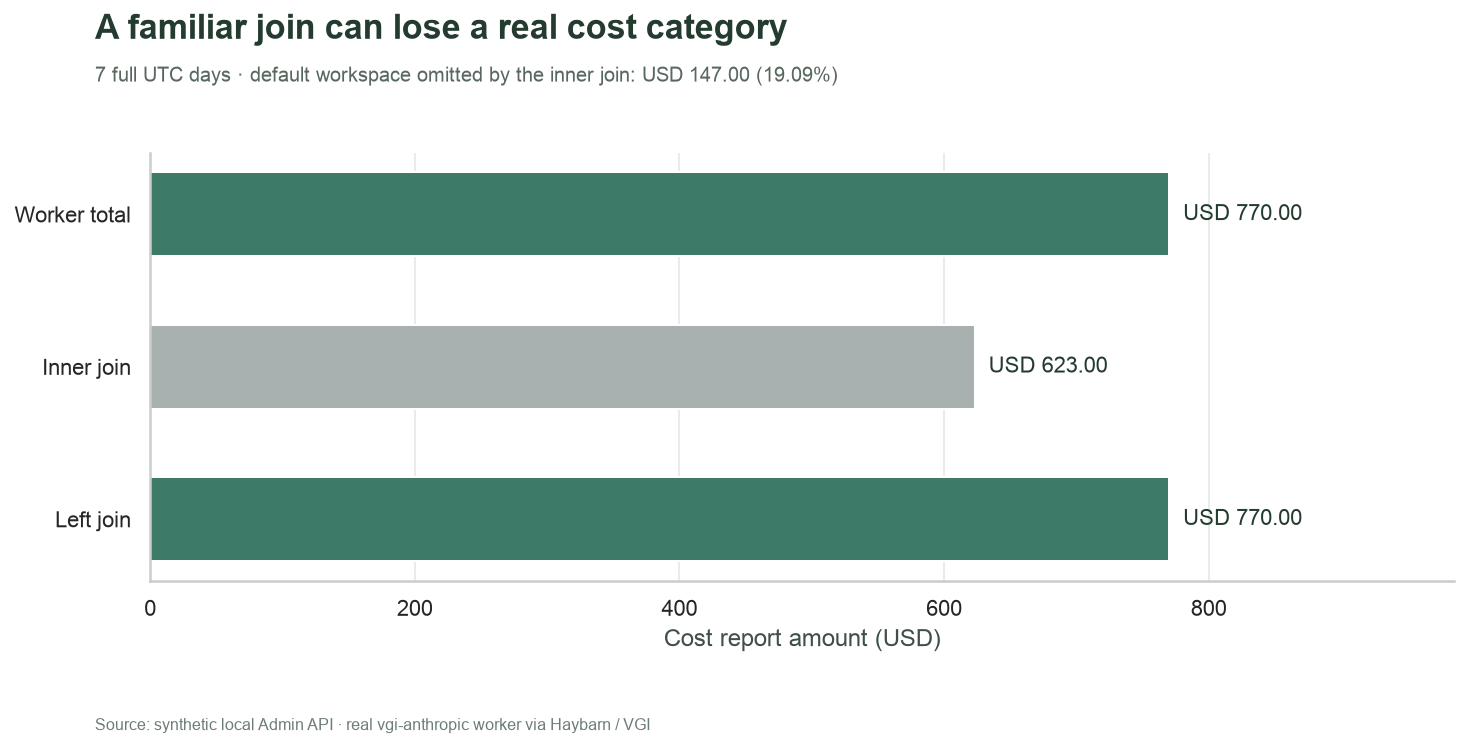

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
values = comparison.usd.astype(float)
bars = ax.barh(comparison.method, values, color=["#3D7B68", "#A8B1B0", "#3D7B68"], height=0.55)
ax.bar_label(bars, labels=[f"USD {v:,.2f}" for v in values], padding=7, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.28)
ax.set_xlabel("Cost report amount (USD)")
ax.grid(axis="y", visible=False)
chart(
    fig,
    "A familiar join can lose a real cost category",
    f"{REPORT_DAYS} full UTC days · default workspace omitted by the inner join: "
    f"USD {r.default_usd:,.2f} ({r.default_share_pct:.2f}%)",
)

## Look at the daily composition

Recovered spend is not a constant percentage of the total. Aggregate the labelled
rows by UTC day and workspace, then calculate each day's default share in SQL.
These invented amounts describe a changing ledger, not token consumption,
productivity, or a forecast. Real cost reports also omit some categories such as
Priority Tier spend; reconciling the report does not prove that it equals an invoice.

In [13]:
%%sql daily <<
SELECT starting_at::DATE AS utc_day, workspace_name, sum(amount_usd) AS usd
FROM labelled_lines GROUP BY 1, 2 ORDER BY 1, 2;

In [14]:
%%sql daily_share <<
SELECT starting_at::DATE AS utc_day,
       100.0 * sum(amount_usd) FILTER (WHERE workspace_id IS NULL) / sum(amount_usd) AS default_share_pct
FROM report_lines GROUP BY 1 ORDER BY 1;

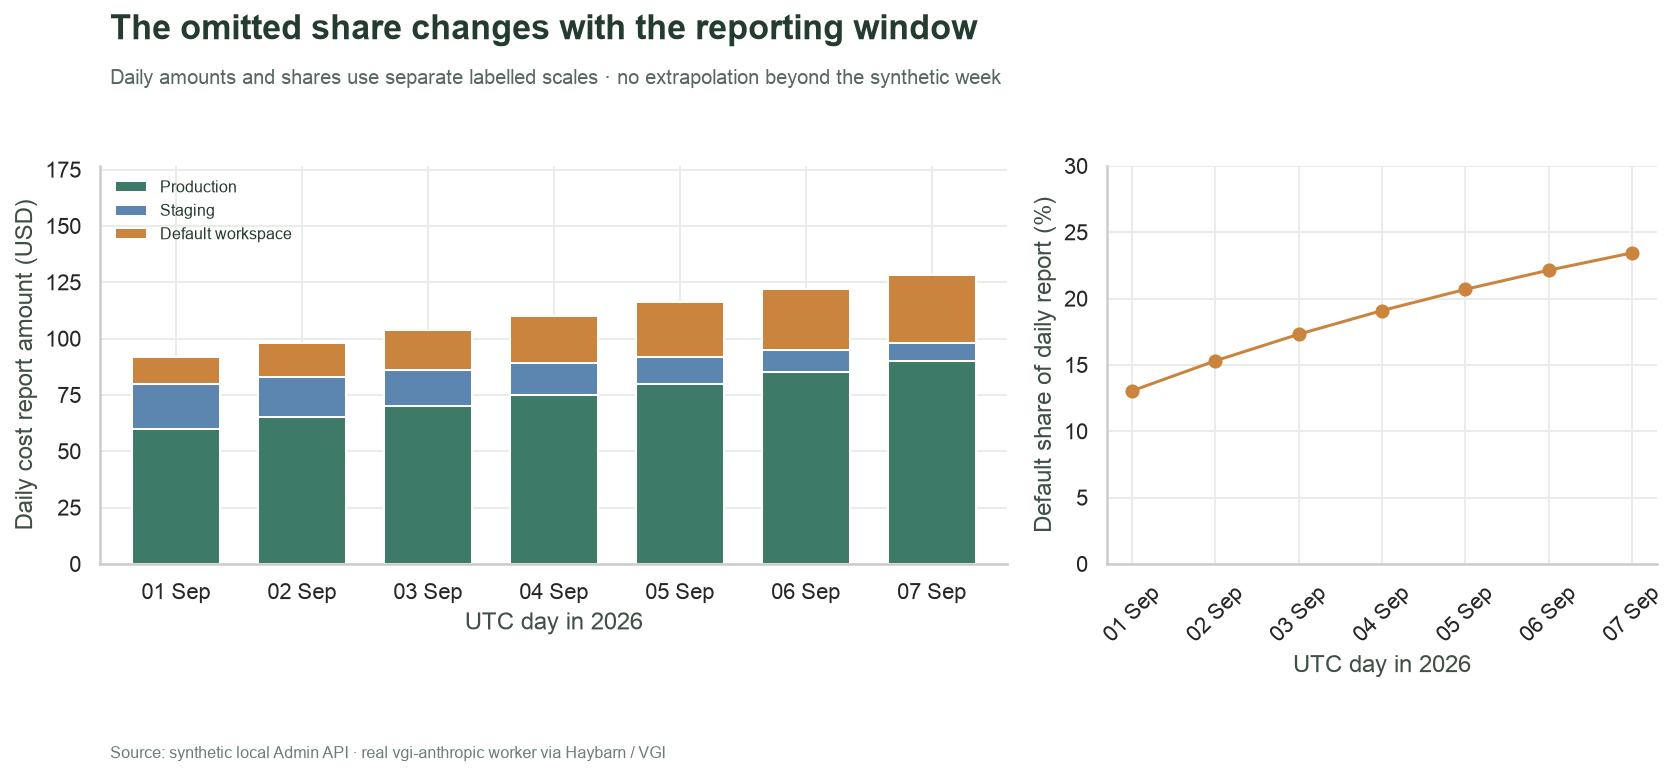

In [15]:
plot_data = daily.pivot(index="utc_day", columns="workspace_name", values="usd")
order = [name for name in COLORS if name in plot_data.columns]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.65, 1]})
plot_data[order].astype(float).plot.bar(stacked=True, color=[COLORS[k] for k in order], ax=axes[0], width=0.7)
axes[0].set_xticklabels([pd.Timestamp(d).strftime("%d %b") for d in plot_data.index], rotation=0)
axes[0].set_xlabel("UTC day in 2026")
axes[0].set_ylabel("Daily cost report amount (USD)")
axes[0].legend(fontsize=8, loc="upper left", ncol=1)
axes[0].set_ylim(0, float(plot_data.sum(axis=1).max()) * 1.38)
axes[1].plot(
    range(len(daily_share)),
    daily_share.default_share_pct.astype(float),
    marker="o",
    color=COLORS["Default workspace"],
)
axes[1].set_xticks(range(len(daily_share)), [pd.Timestamp(d).strftime("%d %b") for d in daily_share.utc_day])
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylabel("Default share of daily report (%)")
axes[1].set_xlabel("UTC day in 2026")
axes[1].set_ylim(0, max(30, float(daily_share.default_share_pct.max()) * 1.25))
chart(
    fig,
    "The omitted share changes with the reporting window",
    "Daily amounts and shares use separate labelled scales · no extrapolation beyond the synthetic week",
)

In [16]:
first = float(daily_share.iloc[0].default_share_pct)
last = float(daily_share.iloc[-1].default_share_pct)
prose(
    f"The default workspace is **{first:.2f}%** of the first selected day and "
    f"**{last:.2f}%** of the last. Its window share is **{r.default_share_pct:.2f}%**, "
    "computed from total dollars, not the unweighted average of daily percentages. "
    "A shorter window can therefore change both the missing amount and its share."
)

The default workspace is **13.04%** of the first selected day and **23.44%** of the last. Its window share is **19.09%**, computed from total dollars, not the unweighted average of daily percentages. A shorter window can therefore change both the missing amount and its share.

## Reconcile the accounting relationships

Check exact cents-to-USD conversion, uniqueness at the requested grain, currency,
join completeness, and grouped-versus-ungrouped daily totals. Unknown directory
IDs remain labelled explicitly. Checks use relationships, not a required ranking
or a hardcoded fixture total.

In [17]:
%%sql checks <<
SELECT 'exact cents / USD relationship' AS check_name,
       bool_and(amount_cents = amount_usd * 100) AS passed FROM report_lines
UNION ALL SELECT 'required values present',
       bool_and(amount_usd IS NOT NULL AND starting_at IS NOT NULL AND currency IS NOT NULL)
       FROM report_lines
UNION ALL SELECT 'USD is the only currency', bool_and(currency = 'USD') FROM report_lines
UNION ALL SELECT 'one row per day and workspace',
       count(*) = (SELECT count(*) FROM (SELECT DISTINCT starting_at, workspace_id FROM report_lines))
       FROM report_lines
UNION ALL SELECT 'directory IDs unique', count(*) = count(DISTINCT id) FROM workspace_directory
UNION ALL SELECT 'left join preserves rows',
       (SELECT count(*) FROM labelled_lines) = (SELECT count(*) FROM report_lines)
UNION ALL SELECT 'grouped daily totals equal worker daily totals', NOT EXISTS (
       SELECT starting_at, sum(amount_usd) AS total FROM report_lines GROUP BY 1
       EXCEPT SELECT starting_at, amount_usd FROM report_totals)
UNION ALL SELECT 'all expected days returned', count(DISTINCT starting_at) = {{REPORT_DAYS}} FROM report_lines;

In [18]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A reconciliation relationship failed"
assert all(
    path in {"/v1/organizations/workspaces", "/v1/organizations/cost_report"} for path, _ in fixture.requests
)
request_counts = pd.Series([path.rsplit("/", 1)[-1] for path, _ in fixture.requests]).value_counts()
display(request_counts.rename("local HTTP GET requests").to_frame())
prose(
    f"**{len(checks)} SQL relationships passed.** "
    "The request counts include pagination of both endpoints. All domain results above "
    "came through the worker; charts read materialized tables without further API calls."
)

,check_name,passed
0,exact cents / USD relationship,True
1,required values present,True
2,USD is the only currency,True
3,one row per day and workspace,True
4,directory IDs unique,True
5,left join preserves rows,True
6,grouped daily totals equal worker daily totals,True
7,all expected days returned,True


,local HTTP GET requests
cost_report,8
workspaces,2


**8 SQL relationships passed.** The request counts include pagination of both endpoints. All domain results above came through the worker; charts read materialized tables without further API calls.

## Experiment: would three days tell the same story?

Change **`REPORT_DAYS = 7` to `REPORT_DAYS = 3`**, restart, and run all. Predict a
smaller missing dollar amount and a smaller default-workspace share: later
synthetic days allocate more spend to that workspace. Compare the first chart's
gap and the SQL window share, then inspect the last point in the daily panel.
The exact reconciliation checks should still pass.

This is a sensitivity check on the selected window, not evidence of a real
organization's trend. Reset to **7** to recover the full synthetic week. The
[guide](README.md) gives the command that saves the experiment separately.

In [19]:
con.close()
close_fixture(fixture, previous_url)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)